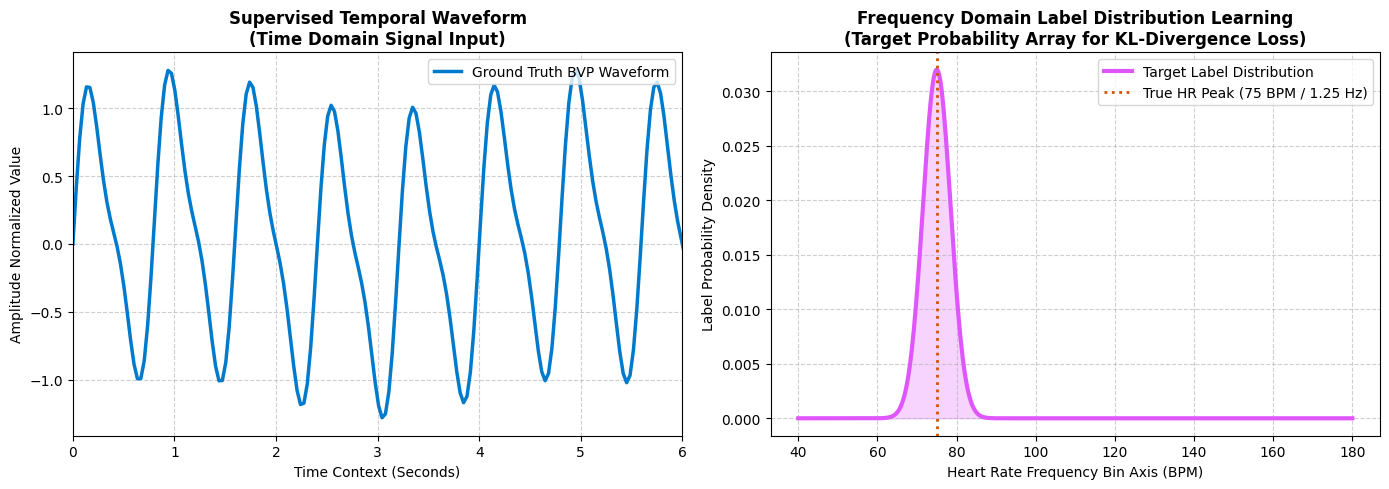

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Pipeline Dimensions & Constants
fs = 30                # Video frame rate (30 Hz proxy)
duration = 10          # 10-second signal window
t = np.linspace(0, duration, duration * fs)
true_hr_bpm = 75       # Ground-truth Heart Rate (75 Beats Per Minute)
true_freq_hz = true_hr_bpm / 60  # Convert to Frequency (1.25 Hz)

# 2. Generate Supervised Temporal Waveform (Clean BVP signal)
# Simulating a realistic pulse profile using a primary frequency and its first harmonic
bvp_waveform = np.sin(2 * np.pi * true_freq_hz * t) + 0.3 * np.sin(2 * np.pi * (true_freq_hz * 2) * t)
# Add a minute amount of baseline respiratory wander
bvp_waveform += 0.15 * np.sin(2 * np.pi * 0.25 * t)

# 3. Generate Frequency Domain Label Distribution (FD-LDL)
# Define the range of candidate heart rates in the physiological band (40 to 180 BPM)
bpm_axis = np.linspace(40, 180, 500)
freq_axis = bpm_axis / 60

# Create a smooth Gaussian distribution centered exactly at the target ground-truth heart rate
std_dev_bpm = 3.5  # Controls the width/variance of the label distribution
target_distribution = norm.pdf(bpm_axis, loc=true_hr_bpm, scale=std_dev_bpm)
target_distribution /= np.sum(target_distribution)  # Normalize to represent valid probabilities

# 4. Plotting the dual visualization panels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left Panel: Supervised Temporal Waveform
ax1.plot(t, bvp_waveform, color='#007acc', lw=2.5, label='Ground Truth BVP Waveform')
ax1.set_title('Supervised Temporal Waveform\n(Time Domain Signal Input)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Time Context (Seconds)', fontsize=10)
ax1.set_ylabel('Amplitude Normalized Value', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right')
ax1.set_xlim(0, 6)  # Focus on a clear 6-second window snippet

# Right Panel: Frequency Domain Label Distribution Learning
ax2.plot(bpm_axis, target_distribution, color='#e056fd', lw=3, label='Target Label Distribution')
ax2.fill_between(bpm_axis, target_distribution, color='#e056fd', alpha=0.25)
ax2.axvline(x=true_hr_bpm, color='#d35400', linestyle=':', lw=2, label=f'True HR Peak ({true_hr_bpm} BPM / {true_freq_hz:.2f} Hz)')
ax2.set_title('Frequency Domain Label Distribution Learning\n(Target Probability Array for KL-Divergence Loss)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Heart Rate Frequency Bin Axis (BPM)', fontsize=10)
ax2.set_ylabel('Label Probability Density', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


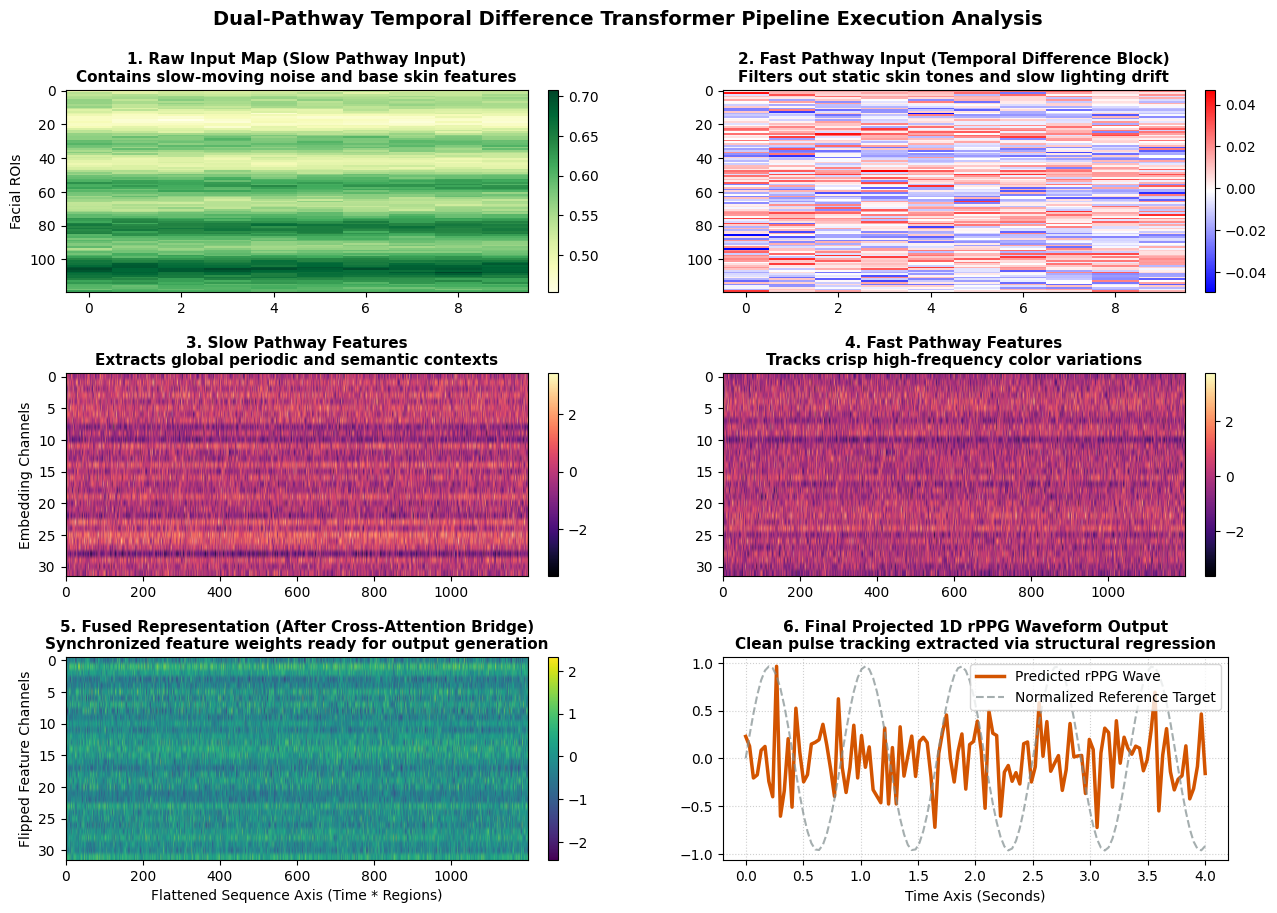

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. ARCHITECTURE DEFINITION
# ==========================================

class TemporalDifferenceBlock(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        # Input shape: [Batch, Channels, Time, Spatial_Regions]
        diff = x[:, :, 1:, :] - x[:, :, :-1, :]
        zero_pad = torch.zeros((x.shape[0], x.shape[1], 1, x.shape[3]), device=x.device)
        return torch.cat([zero_pad, diff], dim=2)


class LateralCrossAttention(nn.Module):
    def __init__(self, embed_dim, num_heads=2):
        super().__init__()
        self.cross_attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, query_pathway, key_value_pathway):
        # Cross-Attention interaction layer
        attn_out, _ = self.cross_attn(query_pathway, key_value_pathway, key_value_pathway)
        return self.norm(query_pathway + attn_out)


class VisualDualPathwayTransformer(nn.Module):
    def __init__(self, spatial_regions=10, time_frames=120, embed_dim=32):
        super().__init__()
        self.time_frames = time_frames
        self.spatial_regions = spatial_regions
        self.embed_dim = embed_dim

        self.slow_embedding = nn.Linear(3, embed_dim)
        self.fast_embedding = nn.Linear(3, embed_dim)
        self.td_block = TemporalDifferenceBlock()
        self.pos_embedding = nn.Parameter(torch.randn(1, time_frames * spatial_regions, embed_dim))

        # Pathways
        encoder_layer_slow = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=2, batch_first=True, dim_feedforward=64)
        self.slow_transformer = nn.TransformerEncoder(encoder_layer_slow, num_layers=1)

        encoder_layer_fast = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=2, batch_first=True, dim_feedforward=64)
        self.fast_transformer = nn.TransformerEncoder(encoder_layer_fast, num_layers=1)

        # Cross-Attention Bridges
        self.slow_to_fast_bridge = LateralCrossAttention(embed_dim, num_heads=2)
        self.fast_to_slow_bridge = LateralCrossAttention(embed_dim, num_heads=2)

        # Output Projectors
        self.fusion = nn.Linear(embed_dim * 2, embed_dim)
        self.rppg_head = nn.Linear(embed_dim * spatial_regions, 1)

    def forward_and_inspect(self, x):
        """
        Custom forward execution path returning intermediate activations for graphing
        """
        B, C, T, N = x.shape
        
        # Fast pathway temporal difference calculation
        fast_diff_raw = self.td_block(x)
        
        # Embed inputs
        slow_in = x.permute(0, 2, 3, 1).reshape(B, T * N, C)
        slow_feat = self.slow_embedding(slow_in) + self.pos_embedding
        
        fast_in = fast_diff_raw.permute(0, 2, 3, 1).reshape(B, T * N, C)
        fast_feat = self.fast_embedding(fast_in) + self.pos_embedding

        # Transformers
        slow_encoded = self.slow_transformer(slow_feat)
        fast_encoded = self.fast_transformer(fast_feat)

        # Lateral Cross-attention exchange
        slow_bridged = self.slow_to_fast_bridge(slow_encoded, fast_encoded)
        fast_bridged = self.fast_to_slow_bridge(fast_encoded, slow_encoded)

        # Fusion Head
        fused_features = torch.cat([slow_bridged, fast_bridged], dim=-1)
        fused_projected = self.fusion(fused_features)
        
        fused_reshaped = fused_projected.view(B, T, N, self.embed_dim)
        fused_collapsed = fused_reshaped.reshape(B, T, N * self.embed_dim)
        rppg_waveform = self.rppg_head(fused_collapsed).squeeze(-1)

        # Collect internal feature maps for plotting (extract first batch item)
        inspection_data = {
            "raw_input": x[0, 1].detach().cpu().numpy(),           # Green channel spatial-temporal block
            "fast_diff": fast_diff_raw[0, 1].detach().cpu().numpy(), # Temporal differences
            "slow_encoded": slow_encoded[0].detach().cpu().numpy().T,
            "fast_encoded": fast_encoded[0].detach().cpu().numpy().T,
            "fused_features": fused_projected[0].detach().cpu().numpy().T,
            "predicted_waveform": rppg_waveform[0].detach().cpu().numpy()
        }
        return rppg_waveform, inspection_data


# ==========================================
# 2. DATA SIMULATION & RENDERING LOOP
# ==========================================

# Setup structural variables
num_rois = 10
frames = 120
t = np.linspace(0, 4, frames)

# Generate synthetic raw target signals (72 BPM cardiac rhythm)
pulse_signal = np.sin(2 * np.pi * 1.2 * t)
noise_trend = np.linspace(0, 1.5, frames)  # Slow lighting drift artifact

simulated_st_map = np.zeros((1, 3, frames, num_rois))
for r in range(num_rois):
    # Add pulse to green channel with static structural skin offset and drift noise
    simulated_st_map[0, 1, :, r] = 0.5 + 0.05 * pulse_signal + 0.1 * noise_trend + np.random.normal(0, 0.01, frames)
    # Red and blue channels get static background information
    simulated_st_map[0, 0, :, r] = 0.6 + np.random.normal(0, 0.01, frames)
    simulated_st_map[0, 2, :, r] = 0.4 + np.random.normal(0, 0.01, frames)

# Convert arrays to PyTorch evaluation tensors
input_tensor = torch.tensor(simulated_st_map, dtype=torch.float32)

# Pass data through the model to retrieve analytical maps
model = VisualDualPathwayTransformer(spatial_regions=num_rois, time_frames=frames)
model.eval()
with torch.no_grad():
    prediction, activations = model.forward_and_inspect(input_tensor)

# ==========================================
# 3. INTERMEDIATE LAYER VISUALIZATION
# ==========================================

fig = plt.figure(figsize=(15, 10))
grid = plt.GridSpec(3, 2, wspace=0.3, hspace=0.4)

# Plot 1: Raw Input Map (Slow Pathway Input)
ax0 = fig.add_subplot(grid[0, 0])
im0 = ax0.imshow(activations["raw_input"], aspect='auto', cmap='YlGn', interpolation='nearest')
ax0.set_title("1. Raw Input Map (Slow Pathway Input)\nContains slow-moving noise and base skin features", fontsize=11, fontweight='bold')
ax0.set_ylabel("Facial ROIs")
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)

# Plot 2: Fast Pathway Input (Temporal Difference Output)
ax1 = fig.add_subplot(grid[0, 1])
im1 = ax1.imshow(activations["fast_diff"], aspect='auto', cmap='bwr', interpolation='nearest')
ax1.set_title("2. Fast Pathway Input (Temporal Difference Block)\nFilters out static skin tones and slow lighting drift", fontsize=11, fontweight='bold')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

# Plot 3: Transformer Encoder Output (Slow Pathway)
ax2 = fig.add_subplot(grid[1, 0])
im2 = ax2.imshow(activations["slow_encoded"], aspect='auto', cmap='magma')
ax2.set_title("3. Slow Pathway Features\nExtracts global periodic and semantic contexts", fontsize=11, fontweight='bold')
ax2.set_ylabel("Embedding Channels")
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

# Plot 4: Transformer Encoder Output (Fast Pathway)
ax3 = fig.add_subplot(grid[1, 1])
im3 = ax3.imshow(activations["fast_encoded"], aspect='auto', cmap='magma')
ax3.set_title("4. Fast Pathway Features\nTracks crisp high-frequency color variations", fontsize=11, fontweight='bold')
fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)

# Plot 5: Bidirectional Cross-Attention Fusion Feature Layer
ax4 = fig.add_subplot(grid[2, 0])
im4 = ax4.imshow(activations["fused_features"], aspect='auto', cmap='viridis')
ax4.set_title("5. Fused Representation (After Cross-Attention Bridge)\nSynchronized feature weights ready for output generation", fontsize=11, fontweight='bold')
ax4.set_ylabel("Flipped Feature Channels")
ax4.set_xlabel("Flattened Sequence Axis (Time * Regions)")
fig.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)

# Plot 6: Final Extracted rPPG Waveform Output
ax5 = fig.add_subplot(grid[2, 1])
ax5.plot(t, activations["predicted_waveform"], color='#d35400', lw=2.5, label='Predicted rPPG Wave')
ax5.plot(t, pulse_signal * np.max(np.abs(activations["predicted_waveform"])), color='#7f8c8d', linestyle='--', alpha=0.7, label='Normalized Reference Target')
ax5.set_title("6. Final Projected 1D rPPG Waveform Output\nClean pulse tracking extracted via structural regression", fontsize=11, fontweight='bold')
ax5.set_xlabel("Time Axis (Seconds)")
ax5.grid(True, linestyle=':', alpha=0.6)
ax5.legend()

plt.suptitle("Dual-Pathway Temporal Difference Transformer Pipeline Execution Analysis", fontsize=14, fontweight='bold', y=0.96)
plt.show()